# 03 · Artists

Questions about the artists The Current has played since Dec. 22, 2005.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from plays import load_plays, display_names, fmt_duration

pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE = "#2a78d6"

plays = load_plays()           # every logged entry
music = plays[plays.is_music]  # just the songs (see 01_scrape.ipynb → "What isn't a song?")

## How many unique artists have been played?

Artists are counted by `artist_key`, the artist name lowercased with accents stripped. Collaborations
("Artist A feat. Artist B") count as their own artist, so this slightly overcounts distinct acts.

In [2]:
plays_per_artist = music.artist_key.value_counts()
n_artists = len(plays_per_artist)

print(f"{n_artists:,} unique artists")
print(f"{(plays_per_artist == 1).sum():,} ({(plays_per_artist == 1).mean():.0%}) were played exactly once")
print(f"{(plays_per_artist >= 1000).sum():,} have been played 1,000+ times")

24,320 unique artists
9,210 (38%) were played exactly once
593 have been played 1,000+ times


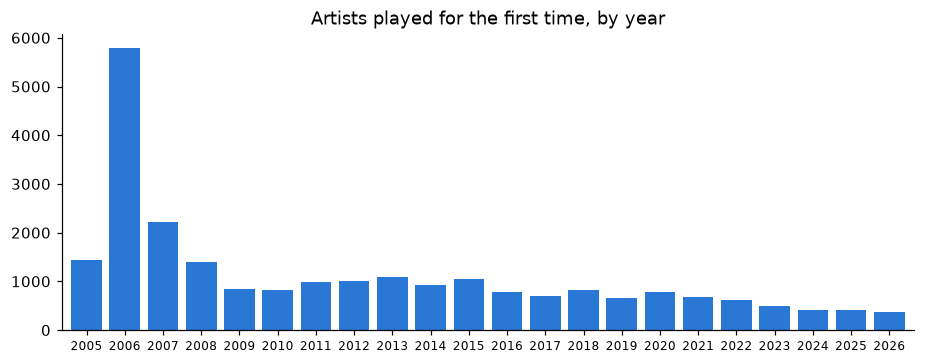

2006 is high because everything is 'new' in the station's first full year.


In [3]:
# New artists per year: how many artists made their first appearance on The Current that year
first_year = music.groupby("artist_key").played_at.min().dt.year
ax = first_year.value_counts().sort_index().plot.bar(color=BLUE, width=0.8, figsize=(10, 3.5))
ax.set(title="Artists played for the first time, by year", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=0, labelsize=8)
plt.show()
print("2006 is high because everything is 'new' in the station's first full year.")

## What artist has The Current played the most?

In [4]:
artist_names = display_names(music, "artist_key", ["artist"])
top_artists = (
    music.groupby("artist_key")
    .agg(plays=("play_id", "size"), songs=("song_key", "nunique"),
         first_played=("played_at", "min"), last_played=("played_at", "max"))
    .join(artist_names)
    .sort_values("plays", ascending=False)
)
top_artists["first_played"] = top_artists.first_played.dt.strftime("%Y-%m-%d")
top_artists["last_played"] = top_artists.last_played.dt.strftime("%Y-%m-%d")
top_artists = top_artists.reset_index(drop=True)[["artist", "plays", "songs", "first_played", "last_played"]]
top_artists.head(25)

,artist,plays,songs,first_played,last_played
0,Prince,12620,472,2005-12-25,2026-10-11
1,Wilco,11002,119,2005-12-22,2026-10-11
2,David Bowie,10803,208,2005-12-23,2026-10-11
3,The Black Keys,10776,74,2005-12-26,2026-10-11
4,Spoon,10378,76,2005-12-23,2026-10-11
5,Beck,10064,112,2005-12-23,2026-10-11
6,Radiohead,8903,91,2005-12-23,2026-10-11
7,R.E.M.,8024,121,2005-12-22,2026-10-10
8,Arcade Fire,7790,53,2005-12-23,2025-01-24
9,Death Cab for Cutie,7785,121,2005-12-22,2026-10-11


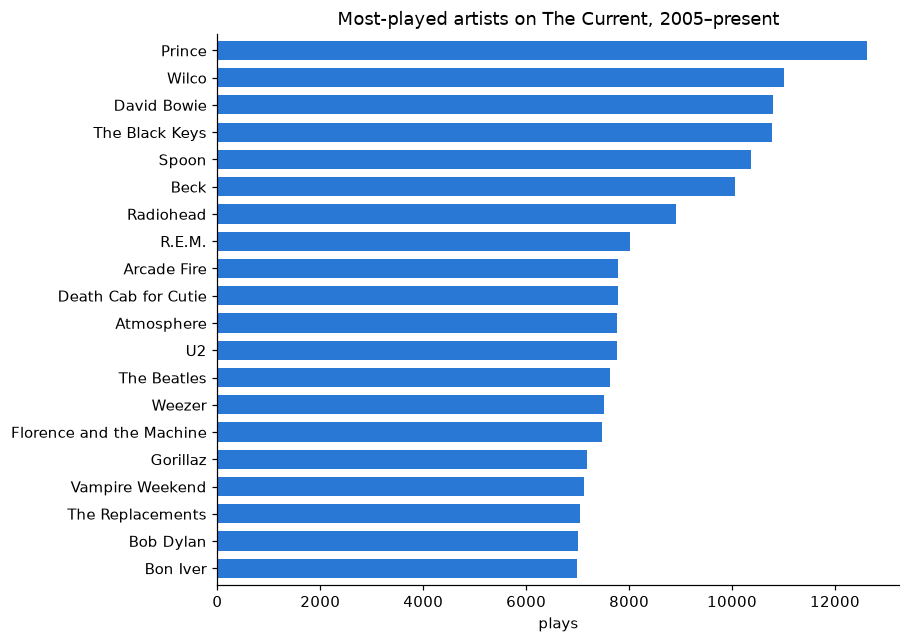

In [5]:
top20 = top_artists.head(20).iloc[::-1]
ax = top20.plot.barh(x="artist", y="plays", color=BLUE, legend=False, figsize=(8, 6.5), width=0.7)
ax.set(title="Most-played artists on The Current, 2005–present", xlabel="plays", ylabel="")
plt.show()

In [6]:
# Most-played artist of each year
year = music.played_at.dt.year.rename("year")
by_year = music.groupby([year, "artist_key"]).size().rename("plays").reset_index()
top_each_year = (
    by_year.sort_values(["year", "plays"], ascending=[True, False])
    .drop_duplicates("year")
    .join(artist_names, on="artist_key")
    .set_index("year")[["artist", "plays"]]
)
top_each_year

,artist,plays
year,,
2005,Leela James,16
2006,Beck,344
2007,Wilco,422
2008,Atmosphere,772
2009,Wilco,823
2010,Mumford and Sons,914
2011,Adele,882
2012,The Black Keys,946
2013,David Bowie,877


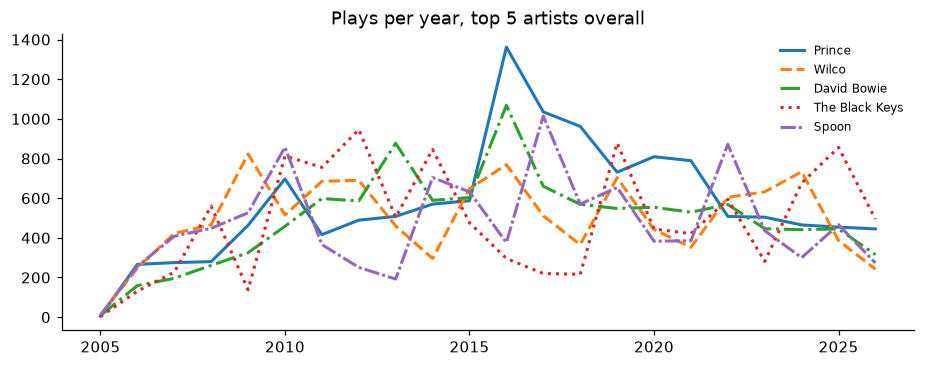

In [7]:
# Each of the overall top 5 artists, plays per year
top5 = top_artists.artist.head(5).tolist()
keys = artist_names[artist_names.artist.isin(top5)].index
trend = by_year[by_year.artist_key.isin(keys)].pivot(index="year", columns="artist_key", values="plays").fillna(0)

fig, ax = plt.subplots(figsize=(10, 3.5))
for k, style in zip(keys, ["-", "--", "-.", ":", (0, (5, 1, 1, 1))]):
    ax.plot(trend.index, trend[k], linestyle=style, lw=2, label=artist_names.loc[k, "artist"])
ax.set(title="Plays per year, top 5 artists overall", ylabel="")
ax.legend(fontsize=8, frameon=False)
plt.show()

## Who has come in for the most 89.3 in-studio performances?

The playlist doesn't record studio visits directly. What it records is every **airing of a song recorded in-studio**:
those are logged with the album **`89.3 In-Studio Performance`**, or with titles like "LIVE IN STUDIO" or
"In-Studio Performance Recorded on …". In-studio recordings are replayed for years, so play counts mostly measure
*replays*. To estimate actual **visits**, we take the date each in-studio track first aired, then group an artist's
tracks into sessions: a new session starts when there's a gap of more than 180 days since that artist's previous new
in-studio track.

**Caveats:**
- This is an estimate. One session's songs sometimes debut months apart, which can create an extra "visit".
- The `89.3 In-Studio Performance` label is used much less after about 2017, so recent sessions are undercounted.

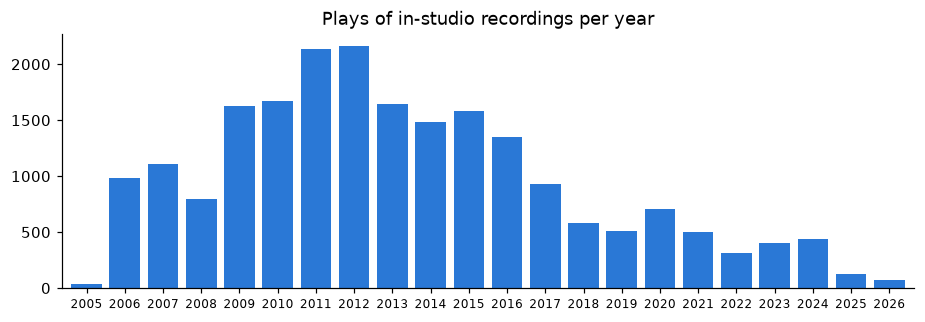

In [8]:
studio = plays[
    (plays.album == "89.3 In-Studio Performance")
    | plays.title.str.contains(r"^(?:live )?in[- ]?st[ud]{2}io\b", case=False, na=False)
]
studio = studio[~studio.artist.str.contains(r"in[- ]?studio|^live in", case=False, na=False)]  # artist must be a real act

ax = studio.groupby(studio.played_at.dt.year).size().plot.bar(color=BLUE, width=0.8, figsize=(10, 3))
ax.set(title="Plays of in-studio recordings per year", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=0, labelsize=8)
plt.show()

In [9]:
SESSION_GAP_DAYS = 180

tracks = (
    studio.assign(title_key=studio.title.str.casefold().str.strip())
    .groupby(["artist_key", "title_key"]).played_at.min()
    .rename("first_aired").reset_index()
    .sort_values(["artist_key", "first_aired"])
)
gap = tracks.groupby("artist_key").first_aired.diff().dt.days
tracks["session"] = (gap.isna() | (gap > SESSION_GAP_DAYS)).groupby(tracks.artist_key).cumsum()

sessions = (
    tracks.groupby("artist_key")
    .agg(est_sessions=("session", "max"), in_studio_tracks=("title_key", "size"),
         first_session=("first_aired", "min"), last_session=("first_aired", "max"))
    .join(studio.groupby("artist_key").size().rename("in_studio_plays"))
    .join(artist_names, how="left")
)
sessions["artist"] = sessions.artist.fillna(display_names(studio, "artist_key", ["artist"]).artist)
sessions["first_session"] = sessions.first_session.dt.strftime("%Y-%m")
sessions["last_session"] = sessions.last_session.dt.strftime("%Y-%m")
sessions = sessions.reset_index(drop=True)[
    ["artist", "est_sessions", "in_studio_tracks", "in_studio_plays", "first_session", "last_session"]
]

print(f"{len(sessions):,} artists have in-studio recordings in the log")
sessions.sort_values(["est_sessions", "in_studio_tracks"], ascending=False).head(25)

1,302 artists have in-studio recordings in the log


,artist,est_sessions,in_studio_tracks,in_studio_plays,first_session,last_session
152,Blitzen Trapper,8,20,95,2007-07,2015-11
618,Lissie,8,19,122,2010-01,2018-08
159,Bob Mould,8,17,134,2005-12,2019-03
263,Dan Wilson,8,17,115,2006-02,2017-09
716,Mike Doughty,8,17,111,2005-12,2015-03
173,Brandi Carlile,8,14,105,2005-12,2021-04
87,Atmosphere,7,19,108,2005-12,2017-03
522,JD McPherson,7,19,376,2012-02,2025-12
704,Metric,7,19,117,2006-12,2022-11
382,Frank Turner,7,16,44,2012-02,2025-06


In [10]:
# By how often their in-studio recordings were played (replays included)
sessions.sort_values("in_studio_plays", ascending=False).head(15)

,artist,est_sessions,in_studio_tracks,in_studio_plays,first_session,last_session
522,JD McPherson,7,19,376,2012-02,2025-12
1102,The Hold Steady,5,14,153,2005-12,2010-05
653,M. Ward,5,13,142,2005-12,2012-06
159,Bob Mould,8,17,134,2005-12,2019-03
1017,Tegan and Sara,6,13,128,2007-11,2016-10
17,Adele,2,7,124,2008-06,2010-12
618,Lissie,8,19,122,2010-01,2018-08
1130,The National,5,18,121,2005-12,2020-04
704,Metric,7,19,117,2006-12,2022-11
529,Jeremy Messersmith,6,15,117,2007-01,2018-03
